# 0) Modul importe

In [ ]:
%pip install ICIW_Plots
%pip install cma
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime
import pandas as pd
import glob
from scipy.constants import R
from scipy.integrate import solve_ivp
from scipy.signal import correlate
from pathlib import Path
import sys
import inspect

from AZA_THB_solver import *
from AZA_THB_tools import *
from AZA_THB_reactor_input import *
from AZA_THB_reactor_output_II import *
from AZA_THB_optimizer_II import Optimizer


if 'ICIWstyle' in plt.style.available:
    plt.style.use('ICIWstyle')

Defaulting to user installation because normal site-packages is not writeableNote: you may need to restart the kernel to use updated packages.




[notice] A new release of pip is available: 26.1.2 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.
The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload



[notice] A new release of pip is available: 26.1.2 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
# validation: stoichiometric matrix correct?

star = np.where(np.array(species) == 'star')[0][0]
CO_s= np.where(np.array(species) == 'CO_s')[0][0]
#C_s = np.where(np.array(species) == 'C_s')[0][0]
COin_s = np.where(np.array(species) == 'COin_s')[0][0]
CH_s = np.where(np.array(species) == 'CH_s')[0][0]
CH2_s = np.where(np.array(species) == 'CH2_s')[0][0]
O_s = np.where(np.array(species) == 'O_s')[0][0]
H_s = np.where(np.array(species) == 'H_s')[0][0]
HCO_s = np.where(np.array(species) == 'HCO_s')[0][0]
OH_s = np.where(np.array(species) == 'OH_s')[0][0]
H2O_s = np.where(np.array(species) == 'H2O_s')[0][0]
x = np.where(np.array(species) == 'x')[0][0]
H_x = np.where(np.array(species) == 'H_x')[0][0]
HCOO_x = np.where(np.array(species) == 'HCOO_x')[0][0]
OH_x = np.where(np.array(species) == 'OH_x')[0][0]
H2O_x = np.where(np.array(species) == 'H2O_x')[0][0]

# calculate element species matrix
C = np.zeros(len(species))
C[CO] = 1
C[CO2] = 1
C[CH4] = 1
#C[C_s] = 1
C[CO_s] = 1
C[COin_s] = 1
C[CH_s] = 1
C[HCO_s] = 1
C[HCOO_x] = 1

O = np.zeros(len(species))
O[CO] = 1
O[CO2] = 2
O[H2O] = 1
O[CO_s] = 1
O[COin_s] = 1
O[O_s] = 1
O[OH_s] = 1
O[H2O_s]= 1
O[HCOO_x] = 2
O[HCO_s] = 1
O[OH_x] = 1
O[H2O_x]=1

H = np.zeros(len(species))
H[H2] = 2
H[CH4] = 4
H[H2O] = 2
H[CH_s] = 1
H[H2O_s] = 2
H[HCO_s] = 1
H[OH_s] = 1
H[H_s] = 1
H[HCO_s] = 1
H[H_x] = 1
H[OH_x] = 1
H[HCOO_x] = 1
H[H2O_x] = 2

S = np.zeros(len(species))
S[star] = 1
#S[C_s] = 1
S[CO_s] = 1
S[COin_s] = 1
S[CH_s] = 1
S[H2O_s] = 1
S[O_s] = 1
S[H_s] = 1
S[HCO_s] = 1
S[OH_s] = 1

X = np.zeros(len(species))
X[x] = 1
X[H_x] = 1
X[OH_x] = 1
X[HCOO_x] = 1
X[H2O_x] = 1

stoich_test = np.vstack([C, O, H, S, X])

# check if element balance is fulfilled for all reactions
mat = np.matmul(nue, stoich_test.T)

for i in np.arange(0, mat.shape[0]):
    if np.sum(mat[i,:]) != 0:
        print(mat[i,:]) 
        raise ValueError(f'Reaction {i+1} is wrong')

# 1) Importe Daten

In [4]:
# Auswertung Experiment
path_data_exp = np.load(r"Data files\exp_data_evaluation_gessys_reac_250nml-min_matrix_250nml_min_2bar_150grad.npy", allow_pickle=True)

# nRTDs
path_nRTDs = np.load(r"Data files\Run_2026-07-30_090759_2bar_150grad_250nml-min_caphsa_reope.npy", allow_pickle=True).item()

In [5]:
# extraktion der experimentellen Daten
# times
t_lin            = path_data_exp.item().get('t_lin')    
     
# averaged cycles
n_avg_bu         = path_data_exp.item().get('n_avg_bu')         
n_avg_bt         = path_data_exp.item().get('n_avg_bt')         
ni_out_cycle     = path_data_exp.item().get('ni_out_cycle')      # averaged cycles

x_i              = ni_out_cycle / np.sum(ni_out_cycle, axis=0) #/ scale # molar amounts

# cycles splitted up in RTD and transient part
ni_RTD_cycle     = path_data_exp.item().get('ni_RTD_cycle')      # calculation of RTD molar flows
ni_trans_cycle   = path_data_exp.item().get('ni_trans_cycle')    # transient molar flows

# normalized cycles
ni_cycle_bu_norm = path_data_exp.item().get('ni_cycle_bu_norm') 
ni_cycle_bt_norm = path_data_exp.item().get('ni_cycle_bt_norm') 
ni_cycle_norm = np.hstack((ni_cycle_bu_norm, ni_cycle_bt_norm)) # normalized cycles

# mass balances
C_balance = path_data_exp.item().get('C_balance')
O_balance = path_data_exp.item().get('O_balance')
O_balance = 0

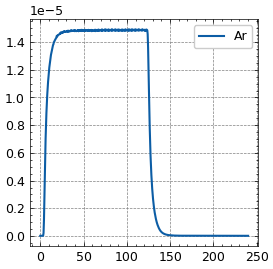

In [6]:
# plots der experimentellen Daten

plt.plot(t_lin,ni_out_cycle[Ar], label='Ar')
plt.legend()
plt.show()
# plt.plot(t_lin,ni_out_cycle[H2], label='H2')
# plt.legend()
# plt.show()
# plt.plot(t_lin,ni_out_cycle[CO2], label='CO2')
# plt.legend()
# plt.show()
# plt.plot(t_lin,ni_out_cycle[CH4], label='CH4')
# plt.legend()
# plt.show()
# plt.plot(t_lin,ni_out_cycle[H2O], label='H2O')
# plt.legend()
# plt.show()
# plt.plot(t_lin,ni_out_cycle[Ne], label='Ne')
# plt.legend()
# plt.show()
# plt.plot(t_lin,ni_out_cycle[He], label='He')
# plt.legend()
# plt.show()

In [7]:
# Verschiebung der x-Achse

switch_delay = 38 # 44 sec
cut_index = np.where(t_lin > 240 - switch_delay)[0][0]  #480
print(cut_index)

ni_out_cycle = np.hstack(( ni_out_cycle[:, cut_index:],ni_out_cycle[:, :cut_index]))
ni_trans_cycle = np.hstack((ni_trans_cycle[:, cut_index:], ni_trans_cycle[:, :cut_index]))
ni_RTD_cycle = np.hstack((ni_RTD_cycle[:, cut_index:], ni_RTD_cycle[:, :cut_index])) 

426


# 2) calculation of imput signal

Berechnung Verweilzeitsummenfunktion:

\begin{align*}
F_\mathrm{i}(t) &= \frac{\dot{n}_{Ar,\mathrm{out}}(t) - \dot{n}_{Ar,\mathrm{out,ss,1}}}{\dot{n}_{Ar,\mathrm{out,ss,2}}-\dot{n}_{Ar,\mathrm{out,ss,1}}}
\end{align*}

In [8]:
# Startwerte für die ODE für den Reactor

t_RTD   = path_nRTDs.get('t_out inlet') # t_out upstream
x_i_RTD = path_nRTDs.get('x_out inlet') # x_out upstream

print(t_RTD.shape)
print(x_i_RTD.shape)
print(t_lin.shape)

CNN_ts = path_nRTDs.get('ts')
CNN_Es = path_nRTDs.get('Es')

(20, 481)
(20, 1, 481)
(506,)


In [9]:
# input = Reactor_input(x_i_RTD = x_i_RTD, 
#                       t_RTD = t_RTD, 
#                       t_lin = t_lin,)

# F_Ar = input.F_Ar()

dt_rtd = CNN_ts[1][1] - CNN_ts[1][0]
input = Reactor_input(x_i_RTD=x_i_RTD, t_RTD=t_RTD, t_lin=t_lin, cycle_time=240.0)
t_rtd, F_Ar = input.F_dosing_step(CNN_ts[0], CNN_Es[0], dt=dt_rtd, bu_fraction=0.5, lead_in=1.0)

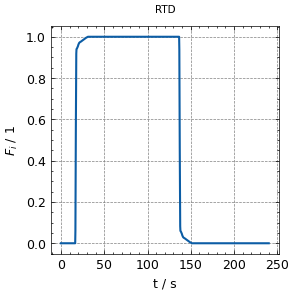

In [10]:
plt.title('RTD')
plt.plot(t_rtd, F_Ar)
plt.xlabel('t / s')
plt.ylabel('$F_i$ / 1')
plt.show()

# 3) imput values für reactor

In [11]:
print(species)

['Ar', 'He', 'H2', 'CO', 'CO2', 'CH4', 'H2O', 'CH6', 'C3H8', 'Ne', 'C4', 'C5', 'C6', 'C2en', 'C3en', 'star', 'CO2_s', 'CO_s', 'COin_s', 'CH_s', 'CH2_s', 'O_s', 'H_s', 'HCO_s', 'OH_s', 'H2O_s', 'x', 'H_x', 'HCOO_x', 'OH_x', 'H2O_x']


In [12]:
# inlet norm volume flows
# V_dot_in_bu = np.array((20, 130, 80, 0, 20, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0)) * 1e-6 / 60 # volume flow bu-phase in m3 s-1
# V_dot_in_bt = np.array((0,  170, 80, 0,  0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0)) * 1e-6 / 60 # volume flow bt-phase in m3 s-1

V_dot_in_bu = np.array((20, 130, 100, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0)) * 1e-6 / 60 # volume flow bu-phase in m3 s-1
V_dot_in_bt = np.array((0,  150, 100, 0,  0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0)) * 1e-6 / 60 # volume flow bt-phase in m3 s-1

# calculation of molar flows from norm volume flows
n_dot_in_bu = V_dot_in_bu * p_STP / (R * T_STP) # molar flow in mol s-1
n_dot_in_bt = V_dot_in_bt * p_STP / (R * T_STP) # molar flow in mol s-1

# calculation of inlet molar flows for each component
# n_dot_i_in = np.zeros((V_dot_in_bu.size, F_Ar.size))
# for i in np.arange(0, len(V_dot_in_bu)):
#     n_dot_i_in[i] = F_Ar * (n_dot_in_bu[i] - n_dot_in_bt[i]) + n_dot_in_bt[i] # molar flow in mol s-1

###
n_dot_i_in = np.array([F_Ar*(n_dot_in_bu[i]-n_dot_in_bt[i]) + n_dot_in_bt[i]
                       for i in range(len(V_dot_in_bu))]) 
# ###    

# repetition of inlet molar flow signal
number_of_periods = 7 # number of periods (just for parameterization)

# n_dot_in = np.hstack((n_dot_i_in, np.hstack(([n_dot_i_in[:,1:] for i in np.arange(1, number_of_periods)]))))
# t_eval = np.hstack((t_lin,np.hstack(([t_lin[1:] + t_lin[-1] * i for i in np.arange(1, number_of_periods)]))))

###
n_dot_in = np.hstack((n_dot_i_in, np.hstack([n_dot_i_in[:, 1:] for i in range(1, number_of_periods)])))
t_eval   = np.hstack((t_rtd,      np.hstack([t_rtd[1:] + t_rtd[-1]*i for i in range(1, number_of_periods)])))
###

#interpolation of molar flow signal
n_dot_func = lambda t:  interpolation_function(t, t_eval, n_dot_in)

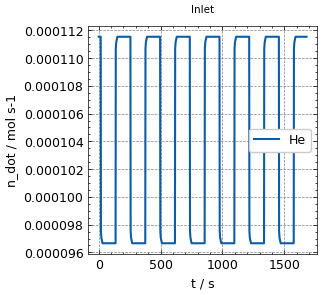

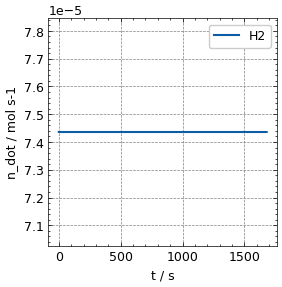

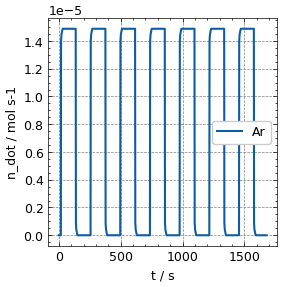

In [13]:
plt.title('Inlet')
plt.plot(t_eval, n_dot_func(t_eval)[He,:], label = species[He])
plt.xlabel('t / s')
plt.ylabel('n_dot / mol s-1')
plt.legend()
plt.show()

plt.plot(t_eval, n_dot_func(t_eval)[H2,:], label = species[H2])
plt.xlabel('t / s')
plt.ylabel('n_dot / mol s-1')
plt.legend()
plt.show()

plt.plot(t_eval, n_dot_func(t_eval)[Ar,:], label = species[Ar])
plt.xlabel('t / s')
plt.ylabel('n_dot / mol s-1')
plt.legend()
plt.show()

# 4) Determine catalyst bed outlet

In [14]:
# operation conditions
p = 2e5 # pressure in Pa   
T = 150 + 273.15 # temperature in K  #180

# reactor geometry
h_cat = 0.01 # catalyst bed length in m
d_R =  1/4 * 0.0254 - 2 * 1e-3 #0.0045 # inner diameter of reactor in m
d_R_c =  1 / 12 * 0.0254 #0.001565 ## outer diameter thermocouple in m
A_R = np.pi* (d_R**2 - d_R_c**2) / 4 # reactor cross-sectional area in m2
V_tot = A_R * h_cat  # total reactor volume in m3

# catalyst properties
m_cat =  50.3e-6 # mass catalyst in kg
m_dil = 50.2e-6 # mass diluent in kg
m_tot = m_cat + m_dil # total mass in kg
n_max =  2 * 7.51e-6 * 1e3 * m_cat  # calculation of entire number of adsorption sites on the active material surface in mol (Baade 2024)
nx_max = O_balance - n_max # estimation of entire number of adsorption sites on the support in mol, 5e-6 mumol/g (Gäßler 2022)
#nx_max = 1.543984466159776e-05 - n_max

rho_TiO2 = 4.26e3 # density titania in kg m-3 (CAS 13463-67-7)
rho_SiC = 3.217e3 # density silicon carbide in kg m-3 (CAS 409-21-2)

eps = 1 - (m_cat / rho_TiO2 + m_dil / rho_SiC) / V_tot # bed porosity in 1
V_R = eps * V_tot # reactor volume in m3

In [15]:
# initial conditions
x_init = np.zeros(surf_start) # initial composition of gas phase in 1
x_init[H2] = 0.4
x_init[He] = 0.6
theta_s_init = np.array([1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]) # initial active material coverage in 1
theta_x_init = np.array([1, 0, 0, 0, 0]) # initial support coverage in 1

y_init = np.hstack((x_init, theta_s_init, theta_x_init)) 

# 5) Initialize optimizer

In [16]:
# residence time data generated according to "https://doi.org/10.1016/j.ces.2025.122454"
CNN_ts = path_nRTDs.get('ts') 
CNN_Es = path_nRTDs.get('Es')

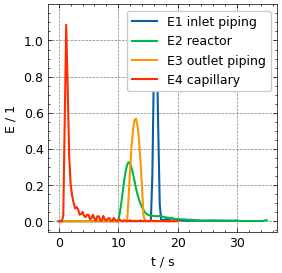

In [17]:
labels=['E1 inlet piping', 'E2 reactor', 'E3 outlet piping', 'E4 capillary']

for i in np.arange(0, len(CNN_ts)):
    plt.plot(CNN_ts[i], CNN_Es[i], label = labels[i])
    plt.xlabel('t / s')
    plt.ylabel('E / 1')
    plt.legend()
plt.show()

In [18]:
optimized_class = Optimizer(ts = CNN_ts, Es = CNN_Es, 
                            n_dot_func = n_dot_func, 
                            t_eval = t_eval, 
                            y_init = y_init, 
                            V_R = V_R, 
                            n_max = n_max, 
                            nx_max = nx_max, 
                            p = p, 
                            T = T, 
                            surf_start = surf_start,
                            n_dot_in_bu = n_dot_in_bu,
                            t_lin = t_lin,
                            ni_out_cycle = ni_out_cycle,
                            ni_trans_cycle = ni_trans_cycle,
                            ni_RTD_cycle = ni_RTD_cycle,
                            number_of_periods = number_of_periods,
                            switch_delay = switch_delay,
                            C_balance = C_balance,
                            O_balance = O_balance
                           )

# 6) run optimizer

In [19]:
def run_optimizer(initial_guess):
    """ optimization runner

    Args:
        initial_guess (array): initial guesses for kinetic constants

    Returns:
        dict: optimization results
    """

    return optimized_class.optimizer(initial_guess)

In [20]:
# this is an exemplary initial guess that is already close to the optimum, for optimization cases replaced by values from LHS Sampler
k_opt = np.array([3.17773820e+03, 3.51228361e+02, 4.84282192e+04, 1.53575113e+05,
 2.99156279e+05, 1.15777043e+04, 2.76270577e+02, 5.54411585e+02,
 1.52367240e+01, 2.81951443e+04, 8.54818775e+01, 1.79306062e+02,
 3.34916780e+02, 8.00782396e+01, 6.77390737e+02, 1.82630237e+05,
 2.45671737e+02, 1.10085193e+02]) # dev_opt ~ 251.63

#sum_opt = run_optimizer(k_opt) # run optimization starting at k_opt

# 7) Retrieve Optimization Results

In [21]:
output = Output(ts = CNN_ts, Es = CNN_Es, 
                n_dot_func = n_dot_func, 
                t_eval = t_eval, 
                y_init = y_init, 
                V_R = V_R, 
                n_max = n_max,  
                nx_max = nx_max,
                p = p, 
                T = T,
                surf_start = surf_start,
                n_dot_in_bu = n_dot_in_bu,
                t_lin = t_lin,
                ni_out_cycle = ni_out_cycle,
                ni_trans_cycle = ni_trans_cycle,
                ni_RTD_cycle = ni_RTD_cycle,
                number_of_periods = number_of_periods,
                switch_delay = switch_delay
                )

In [22]:
# optimum results
n_dot =  output.convolution_function(k_opt, T)
n_dot_trans_int = n_dot['n_dot_trans_int']
n_dot_i_int     = n_dot['n_dot_i_int']
n_dot_theo_int  = n_dot['n_dot_theo_int']
theta_s = n_dot['theta_s']
theta_x = n_dot['theta_x']
x_g = n_dot['x_g']
C_ads_sim = n_dot['C_ads']
O_ads_sim = n_dot['O_ads']

print(k_opt)
#print(error_list[min_ind])

[3.17773820e+03 3.51228361e+02 4.84282192e+04 1.53575113e+05
 2.99156279e+05 1.15777043e+04 2.76270577e+02 5.54411585e+02
 1.52367240e+01 2.81951443e+04 8.54818775e+01 1.79306062e+02
 3.34916780e+02 8.00782396e+01 6.77390737e+02 1.82630237e+05
 2.45671737e+02 1.10085193e+02]


# 8) results

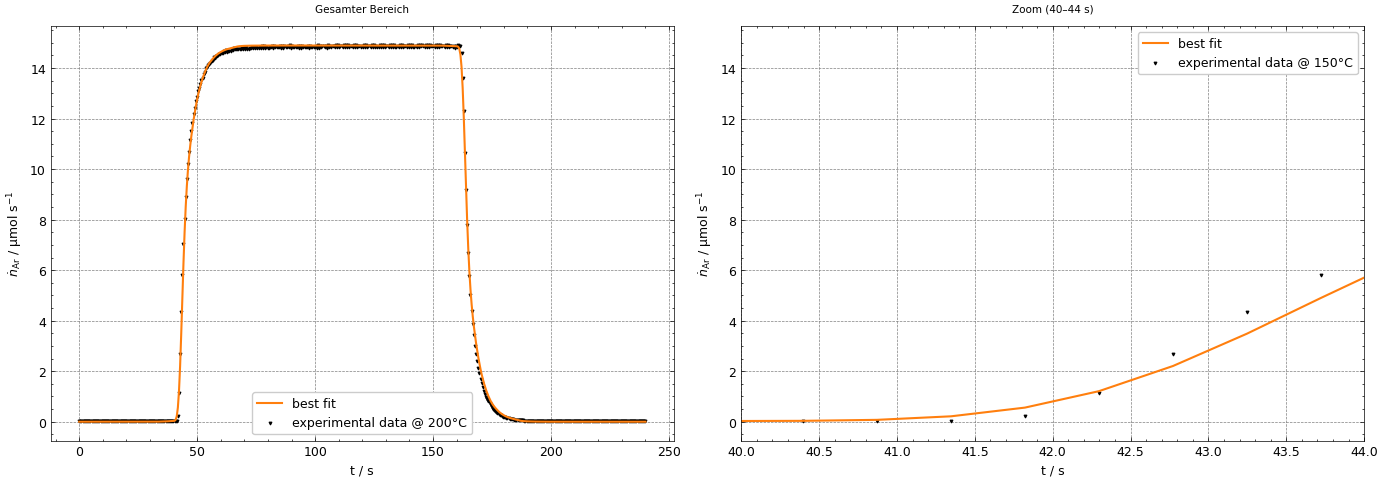

In [23]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Gesamter Plot
ax1.plot(t_lin, n_dot_i_int[Ar,:]/1e-6, label='best fit', color='tab:orange')
ax1.scatter(t_lin, ni_out_cycle[Ar,]/1e-6, label='experimental data @ 200°C', color='black', marker='v', s=3)
ax1.set_xlabel('t / s')
ax1.set_ylabel(r'$\dot{n}_\mathrm{Ar} ~/~ \mathrm{\mu mol~s^{-1}}$')
ax1.set_title('Gesamter Bereich')
ax1.legend()

# Zoom-Plot
x1 = 40
x2 = 44

ax2.plot(t_lin, n_dot_i_int[Ar,:]/1e-6, label='best fit', color='tab:orange')
ax2.scatter(t_lin, ni_out_cycle[Ar,]/1e-6, label='experimental data @ 150°C', color='black', marker='v', s=3)
ax2.set_xlim(x1, x2)
ax2.set_xlabel('t / s')
ax2.set_ylabel(r'$\dot{n}_\mathrm{Ar} ~/~ \mathrm{\mu mol~s^{-1}}$')
ax2.set_title(f'Zoom ({x1}–{x2} s)')
ax2.legend()

plt.tight_layout()
plt.show()

In [ ]:
def check_periodicity(res, cycle_time=240.0, number_of_periods=7, periods_from_end=3,
                      species=None, tol=1e-2, plot=True):
    """Prueft, ob die ODE-Loesung wirklich eingeschwungen ist.
 
    Die periodische Faltung in Stufe E3 (x) E4 setzt voraus, dass die
    ausgeschnittene Periode sich exakt wiederholt. Diese Funktion misst, wie gut
    das erfuellt ist - und ab welcher Periode.
 
    Args:
        res: Rueckgabe von convolution_function
        cycle_time, number_of_periods, periods_from_end: wie an Output uebergeben
        species: Liste von Speziesindizes fuer den Plot (z.B. [Ar, He, CH4])
        tol: Warnschwelle als relative Abweichung (1e-2 = 1 %)
    """
    dg = res['diagnostics']
    t_uni = dg['t_uniform_grid']
    n_dot = dg['n_dot_after_matrix']
 
    dt = t_uni[1] - t_uni[0]
    n_per = int(round(cycle_time / dt)) + 1
 
    def period(p):
        i0 = int(np.argmax(t_uni >= t_uni[0] + p * cycle_time))
        return (None if i0 + n_per > t_uni.size else n_dot[:, i0:i0 + n_per])
 
    def rel_diff(a, b):
        # gleiche Normierung wie in Output: Maximum der spaeteren Periode
        scale = np.max(np.abs(a), axis=1)
        scale[scale == 0] = 1.0
        return np.abs(a - b) / scale[:, np.newaxis]
 
    print(f'periodicity_error (aus diagnostics) = {dg["periodicity_error"]:.3e}'
          f'   entspricht {dg["periodicity_error"]*100:.4f} %\n')
    print(f'Konvergenz von Periode zu Periode (max. rel. Abweichung ueber alle Spezies):')
 
    errs = {}
    for p in range(1, number_of_periods):
        a, b = period(p), period(p - 1)
        if a is None or b is None:
            continue
        errs[p] = float(np.max(rel_diff(a, b)))
        print(f'   Periode {p} gegen {p-1}:  {errs[p]:.3e}  ({errs[p]*100:8.4f} %)')
 
    p_cut = number_of_periods - periods_from_end
    e_cut = errs.get(p_cut, np.nan)
 
    print()
    if e_cut > tol:
        n_need = next((p for p in sorted(errs) if errs[p] <= tol), None)
        print(f'   WARNUNG: {e_cut*100:.3f} % > {tol*100:.1f} % - Loesung ist noch nicht '
              f'eingeschwungen.')
        if n_need is None or number_of_periods - n_need < 2:
            print(f'   -> number_of_periods erhoehen (die Loesung braucht mehr als '
                  f'{number_of_periods} Perioden zum Einschwingen).')
        else:
            print(f'   -> ab Periode {n_need} erfuellt, also periods_from_end = '
                  f'{number_of_periods - n_need} setzen. Sicherer ist trotzdem, '
                  f'number_of_periods zu erhoehen, damit die Randperioden Abstand haben.')
    else:
        print(f'   OK: {e_cut*100:.4f} % <= {tol*100:.1f} %. Die Kachelung ist gerechtfertigt.')
 


res = output.convolution_function(k_opt, T)    # bzw. wie deine Ergebnisvariable heisst
errs = check_periodicity(res, cycle_time=240.0, number_of_periods=number_of_periods,
                         periods_from_end=3, species=[Ar, He, H2], tol=1e-2)

periodicity_error (aus diagnostics) = 1.927e-04   entspricht 0.0193 %

Konvergenz von Periode zu Periode (max. rel. Abweichung ueber alle Spezies):
   Periode 1 gegen 0:  7.299e+06  (729906311.9454 %)
   Periode 2 gegen 1:  8.646e-04  (  0.0865 %)
   Periode 3 gegen 2:  3.225e-04  (  0.0322 %)
   Periode 4 gegen 3:  1.927e-04  (  0.0193 %)
   Periode 5 gegen 4:  1.416e-04  (  0.0142 %)
   Periode 6 gegen 5:  1.163e-04  (  0.0116 %)

   OK: 0.0193 % <= 1.0 %. Die Kachelung ist gerechtfertigt.


# 9) speichern der Ergebnisse

In [ ]:
save = {'t_lin':t_lin, 
         'ni_trans_cycle':ni_trans_cycle,
         'ni_out_cycle':ni_out_cycle,
         'ni_RTD_cycle':ni_RTD_cycle,
         'n_dot_trans_int':n_dot_trans_int,
         'n_dot_theo_int':n_dot_theo_int,
         'n_dot_i_int':n_dot_i_int,
         'theta_s':theta_s,
         'theta_x':theta_x
         }

np.save(r"Optimization Results" + f'\ 31-07-2026_2bar_150grad_caphsa_validierung.npy' ,save)

<>:12: SyntaxWarning: invalid escape sequence '\ '
<>:12: SyntaxWarning: invalid escape sequence '\ '
C:\Users\admin\AppData\Local\Temp\ipykernel_12880\4011970579.py:12: SyntaxWarning: invalid escape sequence '\ '
  np.save(r"Optimization Results" + f'\ 31-07-2026_2bar_150grad_caphsa_validierung.npy' ,save)
